# Vlasov–Poisson | Portfolio figures

Run **Kernel → Restart & Run All**. Uses the uploaded solver modules (or an installed `vlasov` package). Saves publication-ready PNG/PDF figures to `figures/`. Optional GIF at the end. Figures are simulation results, not synthetic illustrations.

**Note:** The numerical growth/damping fit windows are exploratory; check linear-regime validity and convergence before claiming quantitative agreement.

In [1]:
from pathlib import Path
import sys, shutil, importlib.util
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.fft import fft

# If run next to the supplied numbered .py files, create an importable local package.
root = Path.cwd()
modules = ['config','diagnostics','initial_conditions','linear_theory','numerics','plotting','solver']
if importlib.util.find_spec('vlasov') is None:
    pkg = root / 'vlasov'
    pkg.mkdir(exist_ok=True)
    (pkg / '__init__.py').touch()
    for module in modules:
        matches = sorted(root.glob(f'{module}*.py'))
        if not matches:
            raise FileNotFoundError(f'Missing {module}.py: place notebook alongside uploaded modules, or install your vlasov package.')
        shutil.copyfile(matches[0], pkg / f'{module}.py')
    sys.path.insert(0, str(root))

from vlasov.config import Grid
from vlasov.initial_conditions import landau_damping, bump_on_tail, maxwellian
from vlasov.solver import run
from vlasov.numerics import cubic_interpolate, linear_interpolate, compute_rho, compute_efield
from vlasov.linear_theory import dispersion_map, dominant_mode

out = Path('figures'); out.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':115, 'savefig.dpi':220, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.grid':False, 'figure.constrained_layout.use':True})
def save(fig, name):
    for suffix in ('png','pdf'):
        fig.savefig(out / f'{name}.{suffix}', bbox_inches='tight')
    print('Saved:', out / f'{name}.png')

## 1 · Bump-on-tail: nonlinear phase-space evolution

In [2]:
k = 0.5
bot_grid = Grid(xmin=0, xmax=4*np.pi, nx=128, vmin=-8, vmax=8, nv=256)
bot_dt, bot_steps = 0.4, 300
bot_f0 = bump_on_tail(bot_grid, epsilon=0.01, kx=k, eps_bot=0.1, v_bot=3.8, t_bot=0.1)
bot_hist, bot_log_norm, bot_mass, bot_energy = run(bot_f0, bot_grid, bot_dt, bot_steps,
                                                   interp_x=linear_interpolate, interp_v=linear_interpolate)
bot_t = np.arange(bot_steps+1)*bot_dt
print(f'Bump-on-tail simulation: {bot_hist.shape}, t_final={bot_t[-1]:.1f}')

Bump-on-tail simulation: (301, 128, 256), t_final=120.0


Saved: figures\01_phase_space.png


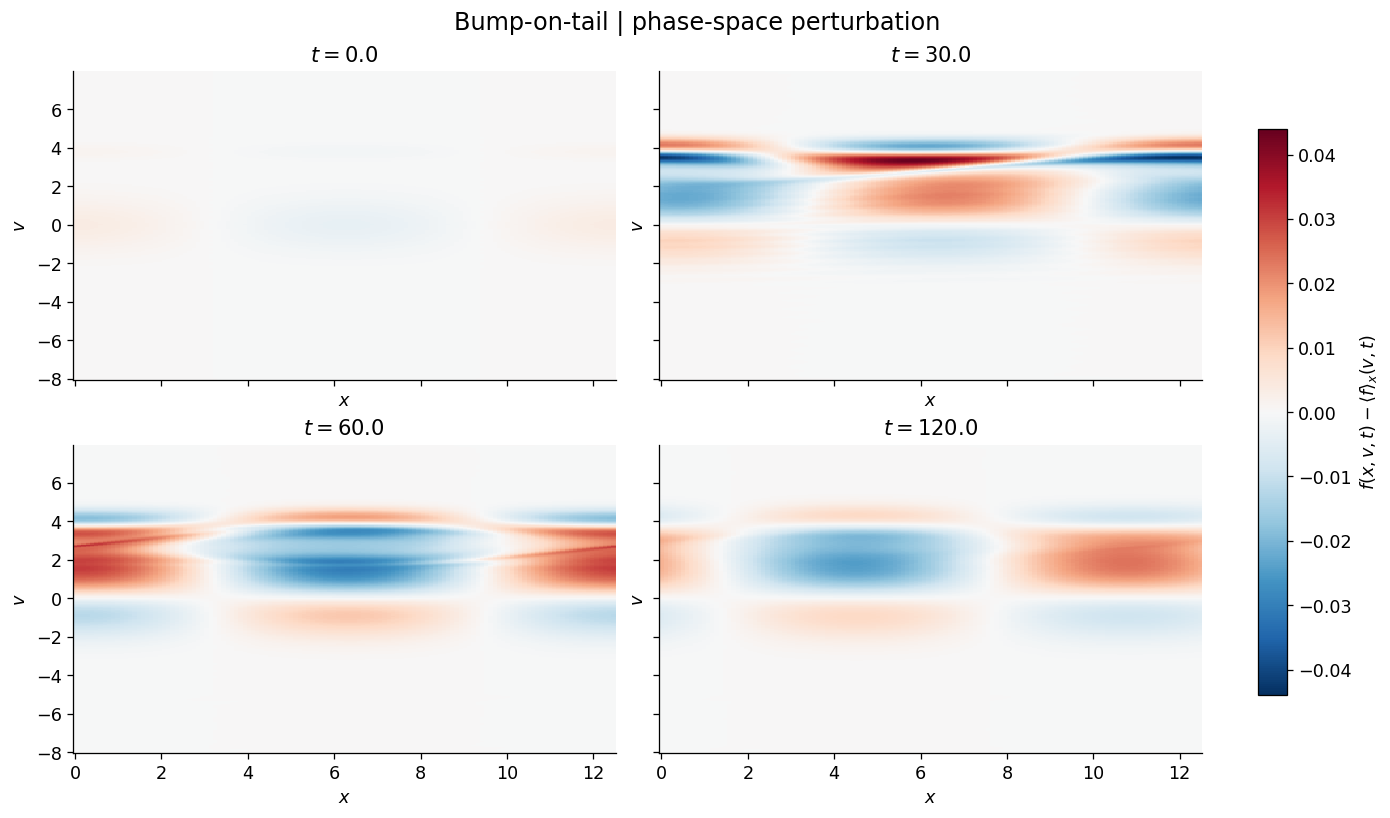

In [3]:
indices = [0, bot_steps//4, bot_steps//2, bot_steps]
# Remove instantaneous spatial mean to emphasize fine phase-space perturbations.
deltas = [bot_hist[j] - bot_hist[j].mean(axis=0, keepdims=True) for j in indices]
limit = max(np.max(np.abs(a)) for a in deltas)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, j, delta in zip(axes.flat, indices, deltas):
    im = ax.pcolormesh(bot_grid.x, bot_grid.v, delta.T, cmap='RdBu_r',
                       norm=TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit), shading='auto', rasterized=True)
    ax.set_title(fr'$t={bot_t[j]:.1f}$')
    ax.set_xlabel('$x$'); ax.set_ylabel('$v$')
fig.colorbar(im, ax=axes, label=r'$f(x,v,t)-\langle f\rangle_x(v,t)$', shrink=.83)
fig.suptitle('Bump-on-tail | phase-space perturbation', fontsize=15)
save(fig, '01_phase_space'); plt.show()

## 2 · Landau damping: electric-field amplitude

Saved: figures\02_landau_damping.png


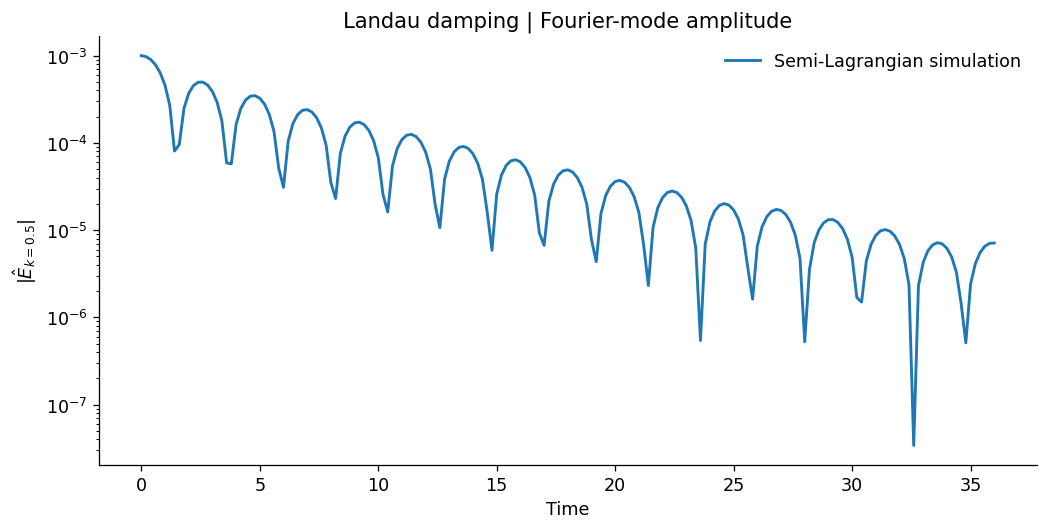

In [4]:
ld_grid = Grid(0, 4*np.pi, 96, -7, 7, 192)
ld_dt, ld_steps = 0.2, 180
ld_f0 = landau_damping(ld_grid, epsilon=0.001, kx=0.5)
ld_hist, ld_log_norm, ld_mass, ld_energy = run(ld_f0, ld_grid, ld_dt, ld_steps)
ld_t = np.arange(ld_steps+1)*ld_dt

def mode_amplitude(history, grid, mode=1):
    return np.array([abs(fft(compute_efield(compute_rho(f,grid.dv),grid.dx))[mode])/grid.nx
                     for f in history])
ld_amp = mode_amplitude(ld_hist, ld_grid)
fig, ax = plt.subplots(figsize=(9,4.5))
ax.semilogy(ld_t, np.maximum(ld_amp, 1e-18), lw=1.8, label='Semi-Lagrangian simulation')
ax.set(xlabel='Time', ylabel=r'$|\hat E_{k=0.5}|$', title='Landau damping | Fourier-mode amplitude')
ax.legend(frameon=False)
save(fig, '02_landau_damping'); plt.show()
# No theory line is asserted here: the oscillatory mode amplitude requires careful envelope fitting.

## 3 · Bump-on-tail dispersion map and unstable root

Unstable root: omega=1.40892+0.11073i
Saved: figures\03_dispersion.png


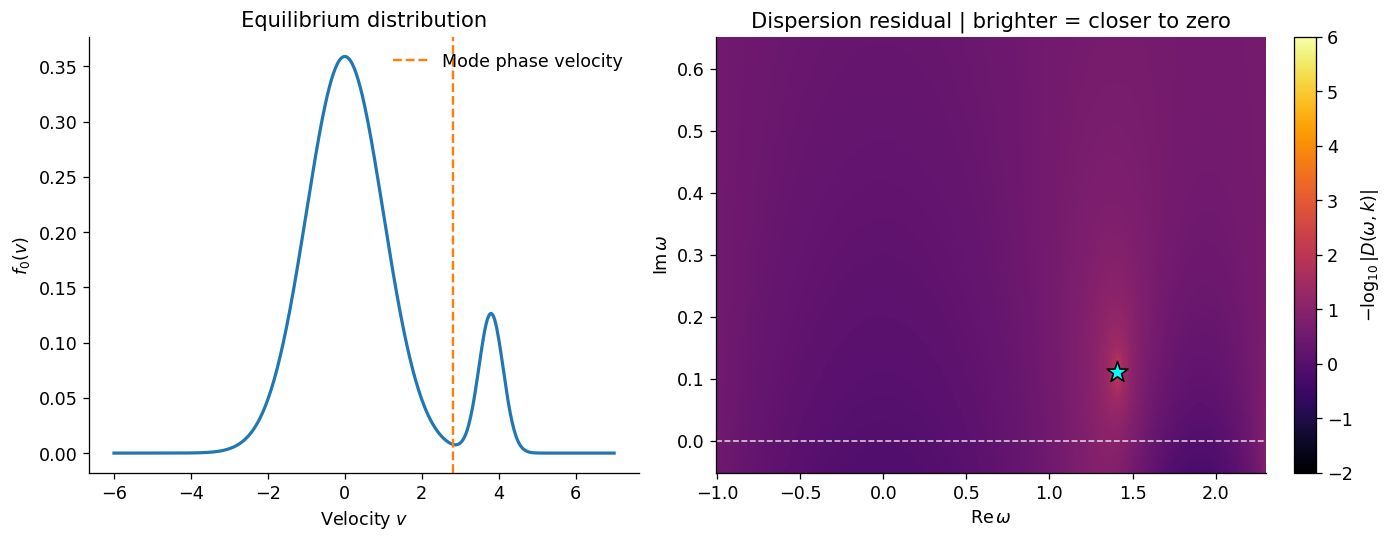

In [5]:
wr = np.linspace(-1, 2.3, 250)
wi = np.linspace(-0.05, 0.65, 175)
W, strength = dispersion_map(k, 0.1, 0.1, 3.8, wr, wi)
root_mode = dominant_mode(k, 0.1, 0.1, 3.8,
                          omega_r=wr, omega_i=np.linspace(1e-4, 0.65, 175))
fig, (ax1, ax2) = plt.subplots(1,2,figsize=(12,4.6))
v = np.linspace(-6,7,500)
feq = 0.9*maxwellian(v) + 0.1*maxwellian(v-3.8, 0.1)
ax1.plot(v,feq,lw=2)
ax1.set(xlabel='Velocity $v$', ylabel='$f_0(v)$', title='Equilibrium distribution')
im = ax2.pcolormesh(W.real,W.imag,np.clip(strength,-2,6),cmap='inferno',vmin=-2,vmax=6,shading='auto',rasterized=True)
ax2.axhline(0,color='white',ls='--',lw=1,alpha=.8)
if root_mode is not None:
    ax2.scatter([root_mode.real],[root_mode.imag],marker='*',s=190,color='cyan',edgecolors='black',zorder=5)
    ax1.axvline(root_mode.real/k,color='C1',ls='--',label='Mode phase velocity')
    ax1.legend(frameon=False)
    print(f'Unstable root: omega={root_mode.real:.5f}+{root_mode.imag:.5f}i')
else:
    print('No unstable root found within the search window.')
ax2.set(xlabel=r'$\operatorname{Re}\omega$',ylabel=r'$\operatorname{Im}\omega$',title='Dispersion residual | brighter = closer to zero')
fig.colorbar(im,ax=ax2,label=r'$-\log_{10}|D(\omega,k)|$')
save(fig,'03_dispersion'); plt.show()

## 4 · Numerical diagnostics: mass, total energy, positivity

Saved: figures\04_diagnostics.png


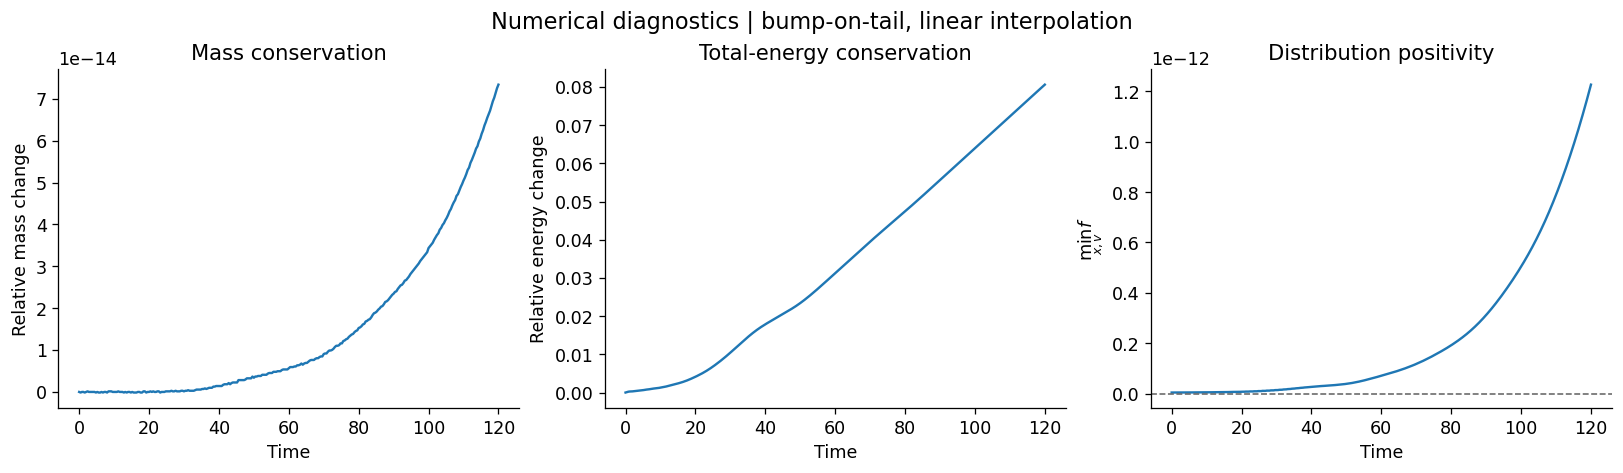

In [6]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
axes[0].plot(bot_t,(bot_mass-bot_mass[0])/abs(bot_mass[0]))
axes[0].set(xlabel='Time',ylabel='Relative mass change',title='Mass conservation')
axes[1].plot(bot_t,(bot_energy-bot_energy[0])/abs(bot_energy[0]))
axes[1].set(xlabel='Time',ylabel='Relative energy change',title='Total-energy conservation')
axes[2].plot(bot_t,bot_hist.min(axis=(1,2)))
axes[2].axhline(0,color='0.4',ls='--',lw=1)
axes[2].set(xlabel='Time',ylabel=r'$\min_{x,v}f$',title='Distribution positivity')
fig.suptitle('Numerical diagnostics | bump-on-tail, linear interpolation',fontsize=14)
save(fig,'04_diagnostics'); plt.show()

## 5 · Optional: animated phase space (GIF)

Set `MAKE_GIF=True` to export. The fixed color scale prevents misleading changes in contrast. GIF export requires Pillow.

In [11]:
MAKE_GIF = True
if MAKE_GIF:
    from matplotlib.animation import FuncAnimation, PillowWriter
    stride = 2
    frames = np.arange(0, bot_steps+1, stride)
    fig, ax = plt.subplots(figsize=(9,4.5))
    image = ax.pcolormesh(bot_grid.x, bot_grid.v, deltas[0].T,
                          cmap='inferno', vmin=-limit, vmax=limit, shading='auto')
    fig.colorbar(image, ax=ax, label=r'$\delta f$')
    ax.set(xlabel='$x$', ylabel='$v$')
    title = ax.set_title('')
    def update(j):
        delta = bot_hist[j] - bot_hist[j].mean(axis=0,keepdims=True)
        image.set_array(delta.T.ravel())
        title.set_text(f'Bump-on-tail | t={bot_t[j]:.1f}')
        return image,title
    anim = FuncAnimation(fig, update, frames=frames, interval=80, blit=False)
    anim.save(out/'05_phase_space.gif', writer=PillowWriter(fps=12))
    plt.close(fig)
    print('Saved:', out/'05_phase_space.gif')
else:
    print('GIF skipped. Set MAKE_GIF=True to create it.')

Saved: figures\05_phase_space.gif
